# 7arf — de l'Arabizi tunisien à l'écriture arabe
>**Projet NLP : génération de texte avec un Encodeur–Décodeur LSTM, écrit from scratch en PyTorch.**

**La problématique:** J'écris souvent à ma mère en Arabizi tunisien, comme beaucoup de Tunisiens sur WhatsApp ou Messenger. Maman comprend très bien le **français** et l'**arabe**, mais pas l'Arabizi : ce sont surtout **les chiffres** qui la perdent. Pour elle, `3`, `7` ou `9` restent des nombres, alors qu'ici ils remplacent des lettres arabes. Résultat : elle ne comprend pas mes messages.

**Notre question** : un réseau de neurones peut-il apprendre à réécrire automatiquement ces messages en écriture arabe, pour que maman puisse les lire ?

| | |
|---|---|
| **Entrée** | Arabizi tunisien : `3andi 5ouya w o5ti` |
| **Sortie** | arabe (convention CODA-TUN) : عندي خويا و اختي |
| **Données** | corpus TArC : 4 504 phrases, 38 036 paires de mots |
| **Modèles** | A sans attention · B avec attention · C BiLSTM · D mots isolés · E teacher forcing décroissant |
| **Meilleur résultat** | modèle C : **CER de test 7,40 ± 0,41 %** |

**Pipeline** : texte brut → prétraitement → vocabulaire → tokenisation → embedding → encodeur → décodeur → entraînement → génération → évaluation.

> **Bonus** : une application web (iPhone → Nokia 3310) et une lecture de captures d'écran par OCR. Elles sont présentées à la fin du notebook.

## 0. Mise en place
Imports, chemins vers les données et choix du GPU s'il est disponible.

In [ ]:
import sys, os, json, math, random, time, re, csv, unicodedata, subprocess
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

# sacrebleu sert uniquement à calculer le BLEU
try:
    import sacrebleu
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"], check=True)
    import sacrebleu

In [ ]:
# j'ai fait le train sur Colab car j'ai besoin du GPU
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/7arf")        
else:
    here = Path.cwd().resolve()
    ROOT = next(p for p in [here, *here.parents] if (p / "data").is_dir())

TARC_TSV    = ROOT / "data" / "tarc" / "tarc_annotated_clean.tsv"
MODELS_DIR  = ROOT / "models"      # poids (best.pt) + vocabulaires
RESULTS_DIR = ROOT / "results"     
for d in (MODELS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
assert TARC_TSV.exists(), f"Corpus introuvable : {TARC_TSV}"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Projet :", ROOT, "| Device :", DEVICE)

Mounted at /content/drive
Projet : /content/drive/MyDrive/7arf | Device : cuda


**Les réglages.** Tous les modèles partagent les mêmes hyperparamètres (`HP`). Seule la configuration (`CONFIGS`) change d'une expérience à l'autre : attention ou non, encodeur simple ou bidirectionnel, fenêtres ou mots isolés, teacher forcing. Un écart de résultat s'explique donc par **une seule modification**.

### À quoi sert la seed ?
Un réseau de neurones utilise du **hasard** : les poids de départ sont tirés au hasard, les batchs sont mélangés au hasard, le dropout éteint des neurones au hasard. La **seed** est le nombre qui fixe ce hasard (`set_seed(seed)` règle Python, NumPy et PyTorch).

Le découpage train / validation / test utilise sa propre seed fixe (13) : tous les modèles voient exactement les mêmes données.

In [ ]:
#ce sont les  réglages de l'expérience 
EXPERIMENTS = ["A", "B", "C", "D", "E"]
SEEDS = {"A": [1, 2, 3], "B": [1, 2, 3], "C": [1, 2, 3], "D": [1], "E": [1, 2, 3]}   # pour D j'ai fait une seule seed car c'est plus long à entraîner
RUN_TRAINING = False     # ici après l'entrainement j'ai mis False pour ne pas entraîner encore une fois 

# ce sont les hyperparamètres communs à tous les modèles pour que la comparaison soit juste
HP = dict(emb_dim=64, enc_hid=256, dec_hid=512, attn_dim=256, dropout=0.3,
          epochs=40, batch_size=64, lr=1e-3, clip=1.0, patience=5,
          min_freq=2,    # lorsqu’un caractère caractère est vu moins de 2 fois il devient <UNK>
          max_len=120,   # c'est la longueur maximale d'une séquence (en caractères)
          chunk=6,       # nombre de mots par exemple 
          max_train=0, max_eval=0)   

#les changements d'une expérience à l'autre : attention / sens de l'encodeur / niveau / teacher forcing (début, fin)
CONFIGS = {
    "A": dict(name="A_noattn",  attention=False, bidirectional=False, level="chunk", tf=(1.0, 1.0)),
    "B": dict(name="B_attn",    attention=True,  bidirectional=False, level="chunk", tf=(1.0, 1.0)),
    "C": dict(name="C_bi_attn", attention=True,  bidirectional=True,  level="chunk", tf=(1.0, 1.0)),
    "D": dict(name="D_word",    attention=True,  bidirectional=True,  level="word",  tf=(1.0, 1.0)),
    "E": dict(name="E_tfdecay", attention=True,  bidirectional=True,  level="chunk", tf=(1.0, 0.5)),
}

# la seed ici fixe tous les tirages aléatoires et si on change la seed, on va mesurer à quel point le résultat dépend de la chance
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(13)

## 1. Introduction

### 1.1 Le problème, vécu au quotidien
J'écris souvent à ma mère en **Arabizi tunisien**, comme beaucoup de Tunisiens sur WhatsApp ou Messenger : `ena n7eb tounes`, `chnowa a7walek`. Maman comprend très bien le français et l'arabe, mais pas l'Arabizi : ce sont surtout **les chiffres** qui la perdent. Pour elle, `3`, `7` ou `9` restent des nombres, pas des lettres : comment deviner que `3andi` se lit عندي ? Il me faudrait réécrire chaque message à la main en arabe.

**7arf** (حرف, « lettre » en arabe) fait cette conversion automatiquement :

| Message envoyé (Arabizi) | Ce que maman peut lire (arabe) |
|---|---|
| `3andi 5ouya w o5ti` | عندي خويا و اختي |
| `ena n7eb tounes` | انا نحبّ تونس |
| `9adech soum hedha` | قدّاش سوم هاذا |

### 1.2 Pourquoi c'est difficile

* Les **chiffres remplacent des lettres** arabes qui n'existent pas en français : le 3 note ع, le 7 note ح, le 9 note ق et le 5 note خ.
* Il n'y a **pas d'orthographe fixe** : `chnowa`, `chnoua`, `chnouwa` désignent le même mot.
* L'Arabizi **mélange l'arabe et le français** : les mots français doivent être recopiés tels quels.
* Les **données annotées sont rares**.

### 1.3 Formulation
C'est une tâche **séquence → séquence**, comme la traduction : on lit une suite de caractères latins $x = (x_1, \dots, x_S)$ et on génère une suite de caractères arabes $y = (y_1, \dots, y_T)$, **un caractère à la fois** :

$$P(y \mid x) = \prod_{t=1}^{T} P(y_t \mid y_1, \dots, y_{t-1},\ x)$$

On travaille au niveau du **caractère** : le modèle apprend des règles (par exemple, `3` devient ع dans tous les mots) qu'il peut appliquer à des mots jamais vus.

## 2. Concepts utilisés

| Concept | Rôle dans 7arf | Section |
|---|---|---|
| Normalisation, tokenisation | nettoyer le texte et le découper en caractères | 4 |
| Vocabulaire, one-hot | associer un numéro à chaque caractère | 4 |
| Embeddings | transformer chaque numéro en vecteur dense appris | 4 |
| LSTM : *hidden state* $h_t$, *cell state* $c_t$ | lire la séquence en gardant une mémoire | 5 |
| Encodeur–Décodeur | lire l'Arabizi, puis écrire l'arabe | 5 |
| Attention de Bahdanau | regarder les bons caractères à chaque pas | 5, modèle B |
| BiLSTM | lire l'entrée dans les deux sens | 5, modèle C |

Les tokens `<SOS>` (début) et `<EOS>` (fin) encadrent chaque sortie du décodeur.

## 3. Données : le corpus TArC, nettoyé

**Source.** Nous utilisons **TArC — *Tunisian Arabish Corpus*** (Gugliotta & Dinarelli, LREC 2020), le premier corpus d'Arabizi tunisien annoté. Il rassemble des textes écrits par des Tunisiens sur les réseaux sociaux, des forums, des blogs et dans des paroles de rap. Chaque mot y est donné en Arabizi (`arabish`) et dans sa forme arabe normalisée CODA (`CODA`).

**Pourquoi j'ai modifié les données.** Ces textes viennent d'Internet, et le corpus original contient **beaucoup de mots grossiers et d'insultes**, en particulier dans les commentaires des réseaux sociaux et les paroles de rap. Mon objectif est d'écrire des messages lisibles pour ma mère : je ne voulais ni qu'un modèle apprenne à générer ce vocabulaire, ni l'afficher dans une démonstration ou une soutenance. J'ai donc **retiré ces mots et les phrases trop vulgaires** avant l'entraînement.

**La version utilisée.** Le fichier nettoyé est `data/tarc/tarc_annotated_clean.tsv`

Le fichier contient **un mot par ligne**, et une ligne `<eos>` marque la fin de chaque phrase.

In [ ]:
raw = pd.read_csv(TARC_TSV, sep="\t", quoting=csv.QUOTE_NONE, dtype=str, keep_default_na=False)
print(raw.shape[0], "lignes,", raw.shape[1], "colonnes :", list(raw.columns))
print("classes :", raw["class"].value_counts().head(5).to_dict())
print("sources :", raw["TYPE"].value_counts().to_dict())
raw[["arabish", "class", "CODA", "TYPE"]].head(8)

43193 lignes, 11 colonnes : ['TYPE', 'data', 'arabish', 'class', 'CODA', 'token', 'pos', 'lemma', 'governorate', 'age', 'gender']
classes : {'arabizi': 27221, 'foreign': 10818, '<eos>': 4546, 'emotag': 607, 'nan': 1}
sources : {'social': 18317, 'forum': 12124, 'blog': 6473, 'rap': 6279}


,arabish,class,CODA,TYPE
0,Ena,arabizi,انا,forum
1,berjoulia,arabizi,بالرجولية,forum
2,kont,arabizi,كنت,forum
3,8ebel,arabizi,هابل,forum
4,3al,arabizi,عال,forum
5,5arja,arabizi,خرجة,forum
6,mais,foreign,mais,forum
7,ba3d,arabizi,بعد,forum


Sur les 11 colonnes, trois suffisent :

* `arabish` : le mot en Arabizi (**entrée**) ;
* `CODA` : le mot en arabe (**cible**) ;
* `class` : `arabizi` (à translittérer) ou `foreign` (mot étranger, la cible est le mot lui-même).

Les émojis et les autres colonnes (POS, lemme, région, âge…) ne servent pas.

In [ ]:
USER = "§"   # les pseudonymes ( ex : m5abbi123...) sont remplacés par un symbole unique
_REPEAT = re.compile(r"(.)\1{3,}")
# caractères invisibles ou décoratifs (espaces de largeur nulle, marques de direction, tatweel ـ)
_INVISIBLE = re.compile("[​-‏‪-‮⁦-⁩﻿ـ]")

def normalize(s, arabic=False):
    s = _INVISIBLE.sub("", unicodedata.normalize("NFKC", s))
    s = s.lower()
    s = re.sub(r"مخب+ّ?ي\d*" if arabic else r"m5abbi\d*", USER, s)
    s = _REPEAT.sub(lambda m: m.group(1) * 3, s)       # "heeeeello" -> "heeello"
    return re.sub(r"\s+", " ", s).strip()

def read_tarc(path):
    # Renvoie une liste de phrases ; une phrase = liste de tokens {src, tgt, cls}
    sents, cur = [], []
    with open(path, encoding="utf-8") as f:
        for row in csv.DictReader(f, delimiter="\t", quoting=csv.QUOTE_NONE):
            if row["arabish"] == "<eos>":                      # fin de phrase
                if cur: sents.append(cur)
                cur = []
            elif row["class"] in ("arabizi", "foreign"):       # on ignore les smileys
                src = normalize(row["arabish"])
                # mot étranger : la cible est identique à la source
                tgt = normalize(row["CODA"], arabic=True) if row["class"] == "arabizi" else src
                if src and tgt:
                    cur.append({"src": src, "tgt": tgt, "cls": row["class"]})
    return sents + ([cur] if cur else [])

sentences = read_tarc(TARC_TSV)
print(len(sentences), "phrases,", sum(map(len, sentences)), "paires (Arabizi → arabe)")
for t in sentences[0][:5]:
    print(t["src"], "→", t["tgt"], f"({t['cls']})")

4504 phrases, 38036 paires (Arabizi → arabe)
ena → انا (arabizi)
berjoulia → بالرجولية (arabizi)
kont → كنت (arabizi)
8ebel → هابل (arabizi)
3al → عال (arabizi)


**Découpage train / validation / test (80 / 10 / 10 %).** On découpe **par phrase**, et les phrases en double vont toutes dans la même partie. Sinon le modèle verrait au test une phrase déjà apprise, et le score serait trop optimiste.

* **train** : apprendre les poids ;
* **validation** : choisir la meilleure époque et arrêter l'entraînement ;
* **test** : mesurer le score final, une seule fois.

In [ ]:
def src_text(sent):
    return " ".join(t["src"] for t in sent)

def split_by_group(sents, seed=13, ratios=(0.8, 0.1, 0.1)):
    # 1) on regroupe les phrases identiques ; 2) on mélange les groupes ; 3) on remplit train, puis valid, puis test
    groups = defaultdict(list)
    for s in sents:
        groups[src_text(s)].append(s)
    keys = sorted(groups)
    random.Random(seed).shuffle(keys)
    quota = [r * len(sents) for r in ratios]
    out = {"train": [], "valid": [], "test": []}
    for k in keys:
        if   len(out["train"]) < quota[0]: name = "train"
        elif len(out["valid"]) < quota[1]: name = "valid"
        else:                              name = "test"
        out[name] += groups[k]
    return out

SPLIT = split_by_group(sentences)

# on fait la vérification : aucune phrase n'apparaît dans deux parties
texts = {n: {src_text(s) for s in ss} for n, ss in SPLIT.items()}
assert not (texts["train"] & texts["valid"]) and not (texts["train"] & texts["test"]) and not (texts["valid"] & texts["test"])
print({n: len(ss) for n, ss in SPLIT.items()}, "phrases, aucune en commun entre les parties")

{'train': 3605, 'valid': 451, 'test': 448} phrases, aucune en commun entre les parties


**Des phrases aux exemples.** 

Une phrase entière peut être longue pour un LSTM : on la coupe en **fenêtres de 6 mots** (modèles A, B, C, E). 

Pour le modèle D, chaque exemple est **un seul mot**, sans contexte.

In [ ]:
def make_examples(sents, level, k=HP["chunk"]):
    examples = []
    for s in sents:
        if level == "word":
            windows = [[t] for t in s]                              # un mot par exemple
        else:
            windows = [s[i:i + k] for i in range(0, len(s), k)]     # fenêtres de k mots
        for w in windows:
            examples.append({"src": " ".join(t["src"] for t in w), "tgt": " ".join(t["tgt"] for t in w)})
    return examples

EX = {lvl: {part: make_examples(ss, lvl) for part, ss in SPLIT.items()} for lvl in ("chunk", "word")}
print({lvl: {p: len(v) for p, v in d.items()} for lvl, d in EX.items()})
print(EX["chunk"]["train"][0])

{'chunk': {'train': 6864, 'valid': 918, 'test': 862}, 'word': {'train': 30046, 'valid': 4167, 'test': 3823}}
{'src': "vous pouvez demander de l \\'", 'tgt': "vous pouvez demander de l \\'"}


In [ ]:
# longueur des exemples (en caractères) : justifie la longueur maximale max_len = 120
for lvl in ("chunk", "word"):
    L = np.array([len(e["src"]) for e in EX[lvl]["train"]])
    T = np.array([len(e["tgt"]) for e in EX[lvl]["train"]])
    print(f"{lvl:5s} | source : moyenne {L.mean():5.1f}, max {L.max():3d} | cible : moyenne {T.mean():5.1f}, max {T.max():3d}"
          f" | tronqués à {HP['max_len']} : {100*(L > HP['max_len']).mean():.2f} % source, {100*(T > HP['max_len']).mean():.2f} % cible")

chunk | source : moyenne  21.2, max  57 | cible : moyenne  19.4, max  55 | tronqués à 120 : 0.00 % source, 0.00 % cible
word  | source : moyenne   4.1, max  47 | cible : moyenne   3.7, max  26 | tronqués à 120 : 0.00 % source, 0.00 % cible


> **.** Les modèles A, B, C, E apprennent sur 6 864 fenêtres et le modèle D sur 30 046 mots. 

## 4. Prétraitement

### 4.1 Normalisation
Avant tout, on uniformise le texte :

| Étape | Exemple | Pourquoi |
|---|---|---|
| Unicode NFKC | `ｃｈｎｏｗａ` → `chnowa` | une même lettre peut avoir plusieurs codes |
| minuscules | `Tounes` → `tounes` | les deux doivent donner la même sortie |
| invisibles et tatweel supprimés | `مـــرحبا` → `مرحبا` | caractères purement décoratifs |
| pseudonymes → `§` | `m5abbi123` → `§` | noms d'utilisateurs anonymisés |
| répétitions ≥ 4 → 3 | `3aslemaaaaa` → `3aslemaaa` | l'allongement expressif ajoute du bruit |

In [ ]:
for s in ["ｃｈｎｏｗａ", "Tounes", "M5abbi123 3aslemaaaaa !!!", "ena​ n7eb"]:
    print(f"{s!r:30} → {normalize(s)!r}")
print(f"{'مـــرحبا':30} → {normalize('مـــرحبا', arabic=True)!r}")

'ｃｈｎｏｗａ'                       → 'chnowa'
'Tounes'                       → 'tounes'
'M5abbi123 3aslemaaaaa !!!'    → '§ 3aslemaaa !!!'
'ena\u200b n7eb'               → 'ena n7eb'
مـــرحبا                       → 'مرحبا'


### 4.2 Tokenisation et vocabulaire
Chaque texte est découpé en **caractères** (l'espace compte comme un caractère).

On construit deux vocabulaires **sur le train seulement**, un pour l'Arabizi et un pour l'arabe. 

Un caractère vu moins de 2 fois devient `<UNK>`.

| Token | id | Rôle |
|---|---|---|
| `<PAD>` | 0 | remplissage, pour avoir des batchs de même longueur |
| `<UNK>` | 1 | caractère inconnu |
| `<SOS>` | 2 | premier symbole donné au décodeur |
| `<EOS>` | 3 | le décodeur s'arrête quand il le produit |

In [ ]:
PAD, UNK, SOS, EOS = "<PAD>", "<UNK>", "<SOS>", "<EOS>"
PAD_ID, UNK_ID, SOS_ID, EOS_ID = 0, 1, 2, 3  # leurs identifiants sont fixes

class CharVocab:
    def __init__(self, chars=()):
        self.itos = [PAD, UNK, SOS, EOS] + list(chars)   # id -> caractère
        self.stoi = {c: i for i, c in enumerate(self.itos)} # caractère -> id

    @classmethod
    def build(cls, texts, min_freq=2):
        counts = Counter(c for t in texts for c in t)
        return cls(sorted(c for c, n in counts.items() if n >= min_freq))

    def __len__(self):
        return len(self.itos)

    def encode(self, text, add_sos_eos=False, max_len=None):
        ids = [self.stoi.get(c, UNK_ID) for c in text][:max_len]   # inconnu -> <UNK>, puis troncature
        return [SOS_ID] + ids + [EOS_ID] if add_sos_eos else ids

    def decode(self, ids):
        chars = []
        for i in ids:
            i = int(i)
            if i == EOS_ID: break    # on s'arrête au premier <EOS>
            if i not in (PAD_ID, SOS_ID): chars.append(self.itos[i])
        return "".join(chars)

    def save(self, path):
        json.dump(self.itos, open(path, "w", encoding="utf-8"), ensure_ascii=False)

    @classmethod
    def load(cls, path):
        v = cls()
        v.itos = json.load(open(path, encoding="utf-8"))
        v.stoi = {c: i for i, c in enumerate(v.itos)}
        return v

# un couple de vocabulaires (source, cible) par niveau (chunk / word)
VOCAB = {lvl: (CharVocab.build([e["src"] for e in EX[lvl]["train"]], HP["min_freq"]),
               CharVocab.build([e["tgt"] for e in EX[lvl]["train"]], HP["min_freq"])) for lvl in EX}
print({lvl: (len(sv), len(tv)) for lvl, (sv, tv) in VOCAB.items()}, "= (taille source, taille cible)")

# aller-retour texte -> ids -> texte pour vérifier que l'encodage est correct
sv, tv = VOCAB["chunk"]
ex = EX["chunk"]["valid"][2]
print("Arabizi :", ex["src"], "->", sv.encode(ex["src"]))
print("Arabe   :", ex["tgt"], "->", tv.encode(ex["tgt"], add_sos_eos=True))
print("retour  :", tv.decode(tv.encode(ex["tgt"], add_sos_eos=True)))

{'chunk': (86, 122), 'word': (86, 122)} = (taille source, taille cible)
Arabizi : tout mignon -> [58, 53, 59, 58, 4, 51, 47, 45, 52, 53, 52]
Arabe   : tout mignon -> [2, 56, 51, 57, 56, 4, 49, 45, 43, 50, 51, 50, 3]
retour  : tout mignon


In [ ]:
# Pourquoi les caractères ? Comparaison avec une tokenisation en mots
train_words = Counter(w for e in EX["word"]["train"] for w in e["src"].split())
test_words = [w for e in EX["word"]["test"] for w in e["src"].split()]
oov_mot = np.mean([w not in train_words for w in test_words])
sv, _ = VOCAB["chunk"]
test_chars = [c for e in EX["chunk"]["test"] for c in e["src"]]
oov_car = np.mean([c not in sv.stoi for c in test_chars])
print(f"Niveau mot       : {len(train_words):5d} mots différents au train, {100*oov_mot:4.1f} % des mots du test jamais vus")
print(f"Niveau caractère : {len(sv):5d} symboles,                   {100*oov_car:4.2f} % des caractères du test inconnus")

Niveau mot       : 10067 mots différents au train, 25.3 % des mots du test jamais vus
Niveau caractère :    86 symboles,                   0.11 % des caractères du test inconnus


→ **Pourquoi les caractères ?** 

Au niveau du mot, un mot du test sur quatre n'a jamais été vu à l'entraînement : le modèle ne pourrait pas l'écrire. Au niveau du caractère, presque tout est connu.

### 4.3 Padding et batchs
Un batch doit être un tableau rectangulaire. 

`collate` complète les séquences courtes avec `<PAD>` et garde leurs vraies longueurs : l'encodeur ne lira pas le padding.

In [ ]:
class TranslitDataset(Dataset):
    def __init__(self, examples, sv, tv, max_len=HP["max_len"]):
        self.src = [sv.encode(e["src"], max_len=max_len) for e in examples]
        self.tgt = [tv.encode(e["tgt"], add_sos_eos=True, max_len=max_len) for e in examples]
    def __len__(self):
        return len(self.src)
    def __getitem__(self, i):
        return i, self.src[i], self.tgt[i]

def collate(batch):
    idx, src, tgt = zip(*batch)
    S, T = max(map(len, src)), max(map(len, tgt))
    src_t = torch.full((len(src), S), PAD_ID, dtype=torch.long)     # tout est d'abord <PAD>...
    tgt_t = torch.full((len(tgt), T), PAD_ID, dtype=torch.long)
    for k, (s, t) in enumerate(zip(src, tgt)):                      # ... puis on écrit les vrais ids
        src_t[k, :len(s)] = torch.tensor(s)
        tgt_t[k, :len(t)] = torch.tensor(t)
    src_len = torch.tensor([max(len(s), 1) for s in src])
    return list(idx), src_t, src_len, tgt_t

def make_loaders(level, seed):
    sv, tv = VOCAB[level]
    train_ex = EX[level]["train"][:HP["max_train"] or None]
    g = torch.Generator().manual_seed(seed)                         # ordre des batchs reproductible
    train = DataLoader(TranslitDataset(train_ex, sv, tv), batch_size=HP["batch_size"], shuffle=True, collate_fn=collate, generator=g)
    valid = DataLoader(TranslitDataset(EX[level]["valid"], sv, tv), batch_size=128, collate_fn=collate)
    return train, valid

# un vrai batch de validation, qu'on réutilise ci-dessous pour vérifier les formes
_, src, src_len, tgt = next(iter(make_loaders("chunk", 1)[1]))
print("src", tuple(src.shape), "| longueurs réelles", src_len[:6].tolist(), "| tgt", tuple(tgt.shape))

src (128, 43) | longueurs réelles [34, 18, 11, 34, 1, 23] | tgt (128, 45)


## 5. Architecture

### 5.1 L'encodeur (Embedding → LSTM)
L'encodeur lit l'Arabizi caractère par caractère. À chaque pas, le LSTM met à jour deux états : le **hidden state** $h_t$, ce qu'il retient à ce pas, et le **cell state** $c_t$, sa mémoire de long terme contrôlée par les portes. Il renvoie toutes les sorties $h_1 \dots h_S$, utilisées par l'attention, ainsi que les états finaux $(h_S, c_S)$, qui résument l'entrée.

In [ ]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, bidirectional=False, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.rnn = nn.LSTM(emb_dim, hid_dim, batch_first=True, bidirectional=bidirectional)
        self.dropout = nn.Dropout(dropout)
        self.n_dir = 2 if bidirectional else 1
        self.out_dim = hid_dim * self.n_dir  # c'est la taille de chaque h_i

    def forward(self, src, src_len):
        emb = self.dropout(self.embedding(src)) # (B, S, E)
        packed = pack_padded_sequence(emb, src_len.cpu(), batch_first=True, enforce_sorted=False)
        out, (h, c) = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))  # (B, S, H*dir)
        # h et c ont la forme (dir, B, H). Avec un BiLSTM on concatène les deux sens -> (1, B, H*dir)
        B = src.size(0)
        h = h.permute(1, 0, 2).reshape(1, B, -1)
        c = c.permute(1, 0, 2).reshape(1, B, -1)
        return out, (h, c)

# test sur un vrai batch : on vérifie les formes
enc = Encoder(len(VOCAB["chunk"][0]), HP["emb_dim"], HP["enc_hid"]).to(DEVICE)
with torch.no_grad():
    out, (h, c) = enc(src.to(DEVICE), src_len.to(DEVICE))
print("entrée           :", tuple(src.shape), "= (B, S)")
print("sorties h_1..h_S :", tuple(out.shape), "= (B, S, H)")
print("états finaux h,c :", tuple(h.shape), tuple(c.shape), "= (1, B, H)")

entrée           : (128, 43) = (B, S)
sorties h_1..h_S : (128, 43, 256) = (B, S, H)
états finaux h,c : (1, 128, 256) (1, 128, 256) = (1, B, H)


### 5.2 L'attention de Bahdanau
**Le problème** : sans attention, toute la fenêtre de 6 mots doit tenir dans un seul vecteur de taille fixe, et les premiers caractères sont vite « oubliés ».

**La solution** : à chaque pas, le décodeur regarde **tous** les $h_i$ et décide lesquels comptent. Pour écrire ع, il doit regarder le `3`.

1. score : $e_{t,i} = v^\top \tanh(W_h h_i + W_s s_{t-1})$, avec $s_{t-1}$ l'état du décodeur ;
2. poids : $\alpha_{t,i} = \text{softmax}_i(e_{t,i})$, dont la somme vaut 1 ;
3. contexte : $c_t = \sum_i \alpha_{t,i} h_i$.

In [ ]:
class BahdanauAttention(nn.Module):
    def __init__(self, enc_dim, dec_dim, attn_dim=256):
        super().__init__()
        self.W_h = nn.Linear(enc_dim, attn_dim, bias=False) # projette les états de l'encodeur
        self.W_s = nn.Linear(dec_dim, attn_dim, bias=False) # projette l'état du décodeur
        self.v = nn.Linear(attn_dim, 1, bias=False) # donne un score à partir du tanh

    def precompute_keys(self, enc_out):
        # W_h h_i ne dépend pas du pas t : on le calcule une seule fois par phrase
        return self.W_h(enc_out)

    def forward(self, s_prev, keys, enc_out, mask):
        scores = self.v(torch.tanh(keys + self.W_s(s_prev).unsqueeze(1))).squeeze(2)   # (B, S)
        scores = scores.masked_fill(~mask, -1e9)       # un <PAD> ne doit jamais recevoir d'attention
        alpha = F.softmax(scores, dim=1)               # poids positifs, somme = 1
        context = torch.bmm(alpha.unsqueeze(1), enc_out).squeeze(1)   # somme pondérée des h_i -> (B, enc_dim)
        return context, alpha

# contrôle sur des données bidon : poids nul sur les <PAD> et somme = 1
att = BahdanauAttention(512, 512, 256)
fake_enc, fake_s = torch.randn(2, 5, 512), torch.randn(2, 512)
fake_mask = torch.tensor([[1, 1, 1, 0, 0], [1, 1, 1, 1, 1]], dtype=torch.bool)   # la 1re phrase a 3 vrais caractères
ctx, alpha = att(fake_s, att.precompute_keys(fake_enc), fake_enc, fake_mask)
print("poids phrase 1 :", alpha[0].detach().numpy().round(3), "<- 0 sur les 2 <PAD>")
print("sommes         :", alpha.sum(1).tolist(), "| contexte :", tuple(ctx.shape))

poids phrase 1 : [0.278 0.276 0.446 0.    0.   ] <- 0 sur les 2 <PAD>
sommes         : [1.0, 1.0] | contexte : (2, 512)


### 5.3 Le décodeur (Embedding → LSTM → Linear → softmax)
Il écrit l'arabe **un caractère à la fois**. À chaque pas, il prend le caractère précédent (`<SOS>` au début), y ajoute le contexte de l'attention, met à jour son LSTM, puis donne une probabilité pour chacun des 122 caractères arabes. Il s'arrête sur `<EOS>`.

In [ ]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, enc_dim, hid_dim, use_attention=True, dropout=0.3, attn_dim=256):
        super().__init__()
        self.use_attention = use_attention
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.dropout = nn.Dropout(dropout)
        if use_attention:
            self.attention = BahdanauAttention(enc_dim, hid_dim, attn_dim)
            self.rnn = nn.LSTM(emb_dim + enc_dim, hid_dim, batch_first=True) # entrée = embedding + contexte
            self.out = nn.Linear(hid_dim + enc_dim + emb_dim, vocab_size) # sortie, contexte et embedding
        else:
            self.rnn = nn.LSTM(emb_dim, hid_dim, batch_first=True)
            self.out = nn.Linear(hid_dim, vocab_size)

    def step(self, y_prev, state, enc_out, keys, mask):
        # Un pas de décodage : renvoie les logits (B, V), le nouvel état et les poids d'attention
        emb = self.dropout(self.embedding(y_prev))                      # (B, E)
        if self.use_attention:
            context, alpha = self.attention(state[0][-1], keys, enc_out, mask)
            out, state = self.rnn(torch.cat([emb, context], dim=1).unsqueeze(1), state)
            feats = torch.cat([out.squeeze(1), context, emb], dim=1)
        else:
            alpha = None
            out, state = self.rnn(emb.unsqueeze(1), state)
            feats = out.squeeze(1)
        return self.out(self.dropout(feats)), state, alpha

### 5.4 Le BiLSTM
Un LSTM qui lit de gauche à droite ne connaît que le passé. Or la suite compte : `s` donne س, mais `ch` donne ش. Le BiLSTM ajoute un second LSTM qui lit de droite à gauche et **concatène** les deux états (2 × 256 = 512).

In [ ]:
enc_bi = Encoder(len(VOCAB["chunk"][0]), HP["emb_dim"], HP["enc_hid"], bidirectional=True).to(DEVICE)
with torch.no_grad():
    out_bi, (h_bi, c_bi) = enc_bi(src.to(DEVICE), src_len.to(DEVICE))
print("LSTM   :", tuple(out.shape), "états finaux", tuple(h.shape))
print("BiLSTM :", tuple(out_bi.shape), "états finaux", tuple(h_bi.shape), "<- les deux sens sont concaténés")

LSTM   : (128, 43, 256) états finaux (1, 128, 256)
BiLSTM : (128, 43, 512) états finaux (1, 128, 512) <- les deux sens sont concaténés


### 5.5 Le modèle complet et le teacher forcing
Un **pont** (`Linear` + `tanh`) transforme l'état final de l'encodeur en état initial du décodeur.

**Teacher forcing** : à l'entraînement, le décodeur reçoit le vrai caractère précédent avec une probabilité $p$, sinon sa propre prédiction. Avec $p = 1$ (modèles A à D), il voit toujours la bonne réponse. Avec $p$ décroissant de 1 à 0,5 (modèle E), il s'habitue à ses propres erreurs, qu'il fera forcément à l'inférence.

In [ ]:
class Seq2Seq(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, emb_dim=64, enc_hid=256, dec_hid=512,
                 bidirectional=False, use_attention=True, dropout=0.3, attn_dim=256):
        super().__init__()
        # on garde la config pour pouvoir reconstruire exactement le même modèle au rechargement
        self.config = dict(src_vocab=src_vocab, tgt_vocab=tgt_vocab, emb_dim=emb_dim, enc_hid=enc_hid, dec_hid=dec_hid,
                           bidirectional=bidirectional, use_attention=use_attention, dropout=dropout, attn_dim=attn_dim)
        self.encoder = Encoder(src_vocab, emb_dim, enc_hid, bidirectional, dropout)
        self.decoder = Decoder(tgt_vocab, emb_dim, self.encoder.out_dim, dec_hid, use_attention, dropout, attn_dim)
        self.bridge_h = nn.Linear(self.encoder.out_dim, dec_hid)  # états de l'encodeur -> état initial du décodeur
        self.bridge_c = nn.Linear(self.encoder.out_dim, dec_hid)

    def encode(self, src, src_len):
        enc_out, (h, c) = self.encoder(src, src_len)
        state = (torch.tanh(self.bridge_h(h)).contiguous(), torch.tanh(self.bridge_c(c)).contiguous())
        keys = self.decoder.attention.precompute_keys(enc_out) if self.decoder.use_attention else None
        mask = src != PAD_ID                                        
        return enc_out, keys, mask, state

    def forward(self, src, src_len, tgt, teacher_forcing=1.0):
        # tgt = <SOS> y1 ... yn <EOS> <PAD>... ; on renvoie les logits qui prédisent tgt[:, 1:]
        enc_out, keys, mask, state = self.encode(src, src_len)
        y = tgt[:, 0] # premier caractère donné au décodeur : <SOS>
        all_logits = []
        for t in range(1, tgt.size(1)):
            logits, state, _ = self.decoder.step(y, state, enc_out, keys, mask)
            all_logits.append(logits)
            if random.random() < teacher_forcing:
                y = tgt[:, t]  # on donne le VRAI caractère
            else:
                y = logits.argmax(1).detach() # on donne la PRÉDICTION du modèle
        return torch.stack(all_logits, dim=1) # (B, T-1, V)

def tf_ratio(epoch, epochs, start=1.0, end=1.0):
    # décroissance linéaire de start (époque 1) à end (dernière époque)
    frac = min(max((epoch - 1) / max(epochs - 1, 1), 0.0), 1.0)   # reste entre 0 et 1
    return start + (end - start) * frac

def build_model(exp):
    cfg = CONFIGS[exp]
    sv, tv = VOCAB[cfg["level"]]
    return Seq2Seq(len(sv), len(tv), HP["emb_dim"], HP["enc_hid"], HP["dec_hid"],
                   bidirectional=cfg["bidirectional"], use_attention=cfg["attention"],
                   dropout=HP["dropout"], attn_dim=HP["attn_dim"])

print("teacher forcing de E aux époques 1, 10, 20, 30, 40 :", [round(tf_ratio(e, HP["epochs"], 1.0, 0.5), 2) for e in (1, 10, 20, 30, 40)])

teacher forcing de E aux époques 1, 10, 20, 30, 40 : [1.0, 0.88, 0.76, 0.63, 0.5]


### 5.6 Les cinq modèles comparés
Chaque modèle ajoute **une seule modification** au précédent :

| | Modèle | Question étudiée |
|---|---|---|
| A | LSTM sans attention | un seul vecteur de contexte suffit-il ? |
| B | A + attention | l'attention améliore-t-elle la génération ? |
| C | B + BiLSTM | le contexte à droite aide-t-il ? |
| D | C sur mots isolés | le contexte de phrase est-il nécessaire ? |
| E | C + teacher forcing décroissant | réduire le biais d'exposition aide-t-il ? |

In [ ]:
# Les cinq architectures : un forward sur un vrai batch, pour vérifier les formes et compter les paramètres
rows = []
for e in EXPERIMENTS:
    m = build_model(e).to(DEVICE)
    lvl = CONFIGS[e]["level"]
    _, s_, sl_, t_ = next(iter(make_loaders(lvl, 1)[1]))
    with torch.no_grad():
        logits = m(s_.to(DEVICE), sl_.to(DEVICE), t_.to(DEVICE))
    rows.append({"exp": e, "attention": CONFIGS[e]["attention"], "bidir": CONFIGS[e]["bidirectional"], "niveau": lvl,
                 "logits (B,T-1,V)": tuple(logits.shape), "paramètres": sum(p.numel() for p in m.parameters())})
pd.DataFrame(rows)

,exp,attention,bidir,niveau,"logits (B,T-1,V)",paramètres
0,A,False,False,chunk,"(128, 44, 122)",1852538
1,B,True,False,chunk,"(128, 44, 122)",2612730
2,C,True,True,chunk,"(128, 44, 122)",3825658
3,D,True,True,word,"(128, 15, 122)",3825658
4,E,True,True,chunk,"(128, 44, 122)",3825658


### 5.7 Générer du texte : greedy et beam search
À l'inférence, il n'y a plus de bonne réponse : le décodeur part de `<SOS>` et réutilise **ses propres prédictions** jusqu'à `<EOS>`. C'est la génération autorégressive.

**Greedy.** À chaque pas, on prend la lettre la plus probable (`argmax`). C'est simple et rapide, mais **une erreur ne se rattrape jamais** : si une lettre est mauvaise, la suite est construite dessus.

**Beam search (recherche en faisceau, k = 5).** On garde les **5 meilleures hypothèses** en parallèle :

1. au premier pas, on garde les 5 débuts les plus probables ;
2. à chaque pas, on prolonge chaque hypothèse avec ses 5 lettres les plus probables ;
3. on ne garde que les 5 séquences de meilleure **probabilité totale** (somme des log-probabilités) ;
4. à la fin, on choisit la meilleure séquence terminée par `<EOS>`.



In [ ]:
@torch.no_grad()
def greedy_decode(self, src, src_len, max_len=None):
    # Renvoie, pour chaque exemple du batch, les ids générés et les poids d'attention
    enc_out, keys, mask, state = self.encode(src, src_len)
    B = src.size(0)
    max_len = max_len or int(src_len.max().item() * 2 + 10)
    y = torch.full((B,), SOS_ID, dtype=torch.long, device=src.device)
    finished = torch.zeros(B, dtype=torch.bool, device=src.device)
    outs, alphas = [], []
    for _ in range(max_len):
        logits, state, alpha = self.decoder.step(y, state, enc_out, keys, mask)
        y = logits.argmax(1)                         # caractère le plus probable
        outs.append(y); alphas.append(alpha)
        finished |= (y == EOS_ID)
        if finished.all(): break                     # tout le batch a fini
    outs = torch.stack(outs, 1).tolist()
    seqs, atts = [], []
    for b in range(B):
        n = outs[b].index(EOS_ID) if EOS_ID in outs[b] else len(outs[b])    # on coupe au premier <EOS>
        seqs.append(outs[b][:n])
        if alphas[0] is None:
            atts.append(None)
        else:   # poids d'attention de l'exemple b : (n+1 pas, longueur réelle de la source)
            atts.append(torch.stack([a[b, :int(src_len[b])] for a in alphas[:n + 1]]).cpu())
    return seqs, atts

Seq2Seq.greedy_decode = greedy_decode

In [ ]:
@torch.no_grad()
def beam_decode(self, src, src_len, beam_size=5, max_len=None, len_penalty=0.7):
    # Un seul exemple à la fois (src de forme (1, S)). Version simple : on fait avancer chaque hypothèse séparément.
    enc_out, keys, mask, state = self.encode(src, src_len)
    max_len = max_len or int(src_len.item() * 2 + 10)
    beams = [([SOS_ID], 0.0, state)]          # chaque hypothèse = (ids, log-proba cumulée, état du décodeur)
    finished = []
    for _ in range(max_len):
        candidates = []
        for seq, score, st in beams:
            y = torch.tensor([seq[-1]], device=src.device)
            logits, new_st, _ = self.decoder.step(y, st, enc_out, keys, mask)
            log_p = F.log_softmax(logits, dim=-1)[0]
            top_lp, top_id = log_p.topk(beam_size)
            for lp, tok in zip(top_lp.tolist(), top_id.tolist()):
                candidates.append((score + lp, seq + [tok], new_st))
        candidates.sort(key=lambda c: c[0], reverse=True)
        beams = []
        for score, seq, st in candidates[:beam_size]:
            if seq[-1] == EOS_ID:
                finished.append((seq, score / (len(seq) - 1) ** len_penalty))    # hypothèse terminée
            else:
                beams.append((seq, score, st))
        if not beams or len(finished) >= beam_size: break
    if not finished:                          # aucune n'a atteint <EOS> : on prend les hypothèses en cours
        finished = [(s, sc / max(len(s) - 1, 1) ** len_penalty) for s, sc, _ in beams]
    best = max(finished, key=lambda f: f[1])[0]
    return [t for t in best[1:] if t != EOS_ID]

Seq2Seq.beam_decode = beam_decode

In [ ]:
@torch.no_grad()
def attention_along(model, src, src_len, out_ids):
    # Rejoue une sortie déjà décidée (par le beam) pour récupérer les poids d'attention de chaque pas
    enc_out, keys, mask, state = model.encode(src, src_len)
    y = torch.tensor([SOS_ID], device=src.device)
    rows = []
    for tok in out_ids:
        _, state, a = model.decoder.step(y, state, enc_out, keys, mask)
        rows.append(a[0, :int(src_len[0])].cpu())
        y = torch.tensor([tok], device=src.device)
    return torch.stack(rows) if rows else None

def transliterate(model, sv, tv, text, beam=0):
    # Texte arabizi (déjà normalisé) -> (texte arabe, poids d'attention ou None)
    ids = sv.encode(text, max_len=HP["max_len"]) or [UNK_ID]
    src, src_len = torch.tensor([ids], device=DEVICE), torch.tensor([len(ids)])
    if beam > 1:
        out = model.beam_decode(src, src_len, beam_size=beam)
        att = attention_along(model, src, src_len, out) if model.decoder.use_attention else None
        return tv.decode(out), att
    seqs, atts = model.greedy_decode(src, src_len)
    return tv.decode(seqs[0]), atts[0]

## 6. Entraînement

| Élément | Choix |
|---|---|
| Perte | entropie croisée par caractère (le padding est ignoré) |
| Optimiseur | Adam, learning rate 0,001, divisé par 2 si la validation stagne |
| Batch / époques | 64 / 40 au maximum |
| Régularisation | dropout 0,3, gradient écrêté à 1 |
| Early stopping | arrêt après 5 époques sans amélioration du CER de validation |

À chaque époque, on mesure la perte et le **CER** (taux d'erreur par caractère) sur la validation, et on sauvegarde le meilleur modèle dans `best.pt`.

In [ ]:
def levenshtein(a, b):
    # distance d'édition : nombre minimal d'insertions, suppressions et substitutions pour passer de a à b
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1,  # suppression
                           cur[j - 1] + 1, # insertion
                           prev[j - 1] + (x != y)))  # substitution (0 si identiques)
        prev = cur
    return prev[-1]

def cer(preds, refs):
    # Character Error Rate = (somme des distances d'édition) / (nombre de caractères de référence)
    return sum(levenshtein(p, r) for p, r in zip(preds, refs)) / max(sum(len(r) for r in refs), 1)

print("CER('كتب' vs 'كتاب') =", cer(["كتب"], ["كتاب"]), "-> 1 caractère manquant sur 4")

def predict(model, loader, tv):
    # Prédictions greedy pour tout un DataLoader, remises dans l'ordre des exemples
    model.eval()
    preds = {}
    with torch.no_grad():
        for idx, src, src_len, _ in loader:
            seqs, _ = model.greedy_decode(src.to(DEVICE), src_len.to(DEVICE))
            for i, s in zip(idx, seqs):
                preds[i] = tv.decode(s)
    return [preds[i] for i in range(len(preds))]

def eval_loss(model, loader, crit):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for _, src, src_len, tgt in loader:
            src, src_len, tgt = src.to(DEVICE), src_len.to(DEVICE), tgt.to(DEVICE)
            logits = model(src, src_len, tgt, teacher_forcing=1.0)
            k = (tgt[:, 1:] != PAD_ID).sum().item()  # nombre de vrais caractères (sans padding)
            total += crit(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1)).item() * k
            n += k
    return total / max(n, 1)

CER('كتب' vs 'كتاب') = 0.25 -> 1 caractère manquant sur 4


In [ ]:
def train_epoch(model, loader, crit, opt, tf):
    model.train()
    total, n = 0.0, 0
    for _, src, src_len, tgt in loader:
        src, src_len, tgt = src.to(DEVICE), src_len.to(DEVICE), tgt.to(DEVICE)
        logits = model(src, src_len, tgt, teacher_forcing=tf)
        loss = crit(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), HP["clip"])    # évite les gradients explosifs
        opt.step()
        k = (tgt[:, 1:] != PAD_ID).sum().item()
        total += loss.item() * k
        n += k
    return total / n

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    json.dump(obj, open(path, "w", encoding="utf-8"), indent=1, ensure_ascii=False)

def train_run(exp, seed):
    cfg = CONFIGS[exp]
    run = f"{cfg['name']}_s{seed}"
    mdir = MODELS_DIR / run
    mdir.mkdir(parents=True, exist_ok=True)
    sv, tv = VOCAB[cfg["level"]]
    sv.save(mdir / "src_vocab.json"); tv.save(mdir / "tgt_vocab.json")  # indispensables pour recharger le modèle

    set_seed(seed) # poids initiaux différents selon la seed
    model = build_model(exp).to(DEVICE)
    train_loader, val_loader = make_loaders(cfg["level"], seed)
    val_refs = [e["tgt"] for e in EX[cfg["level"]]["valid"]]
    crit = nn.CrossEntropyLoss(ignore_index=PAD_ID)
    opt = torch.optim.Adam(model.parameters(), lr=HP["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)

    best_cer, bad_epochs, history = math.inf, 0, []
    for epoch in range(1, HP["epochs"] + 1):
        t0 = time.time()
        tf = tf_ratio(epoch, HP["epochs"], *cfg["tf"])
        train_loss = train_epoch(model, train_loader, crit, opt, tf)
        val_loss = eval_loss(model, val_loader, crit)
        val_cer = cer(predict(model, val_loader, tv), val_refs)
        sched.step(val_cer)
        history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss, val_cer=val_cer, tf=tf))
        print(f"{run} ép {epoch:2d} | train {train_loss:.3f} | val {val_loss:.3f} | CER val {100*val_cer:5.2f} % | tf {tf:.2f} | {time.time()-t0:.0f}s")

        if val_cer < best_cer - 1e-4:  # amélioration : on sauvegarde ce modèle
            best_cer, bad_epochs = val_cer, 0
            torch.save({"state_dict": model.state_dict(), "config": model.config, "epoch": epoch, "val_cer": val_cer}, mdir / "best.pt")
        else:
            bad_epochs += 1
            if bad_epochs >= HP["patience"]:  # early stopping
                print(f"{run} : arrêt anticipé (pas d'amélioration depuis {HP['patience']} époques)")
                break
    save_json({"run": run, "exp": exp, "seed": seed, "best_val_cer": best_cer, "history": history}, mdir / "train_summary.json")
    return run

### 6.1 Lancer les expériences
Ci-dessous, le **journal réel de l'entraînement** des 13 runs, tel qu'il a été produit sur Colab (GPU T4) : pour chaque époque, la perte train et validation, le CER de validation, la probabilité de teacher forcing et la durée. Si vous relancez la cellule avec `RUN_TRAINING = False`, elle affiche seulement un message, car les modèles sont déjà entraînés.

In [ ]:
if RUN_TRAINING:
    for exp in EXPERIMENTS:
        for seed in SEEDS[exp]:
            train_run(exp, seed)
else:
    print("RUN_TRAINING = False : aucun entraînement lancé, on évalue les modèles déjà sauvegardés.")

A_noattn_s1 ép  1 | train 3.142 | val 2.682 | CER val 170.33 % | tf 1.00 | 10s
A_noattn_s1 ép  2 | train 2.564 | val 2.436 | CER val 79.00 % | tf 1.00 | 8s
A_noattn_s1 ép  3 | train 2.377 | val 2.295 | CER val 81.71 % | tf 1.00 | 9s
A_noattn_s1 ép  4 | train 2.263 | val 2.225 | CER val 85.07 % | tf 1.00 | 9s
A_noattn_s1 ép  5 | train 2.169 | val 2.128 | CER val 83.58 % | tf 1.00 | 8s
A_noattn_s1 ép  6 | train 2.072 | val 2.050 | CER val 75.57 % | tf 1.00 | 9s
A_noattn_s1 ép  7 | train 2.015 | val 2.009 | CER val 76.20 % | tf 1.00 | 8s
A_noattn_s1 ép  8 | train 1.970 | val 1.967 | CER val 74.83 % | tf 1.00 | 9s
A_noattn_s1 ép  9 | train 1.920 | val 1.927 | CER val 76.13 % | tf 1.00 | 9s
A_noattn_s1 ép 10 | train 1.874 | val 1.887 | CER val 74.19 % | tf 1.00 | 8s
A_noattn_s1 ép 11 | train 1.827 | val 1.849 | CER val 75.92 % | tf 1.00 | 9s
A_noattn_s1 ép 12 | train 1.782 | val 1.810 | CER val 73.35 % | tf 1.00 | 8s
A_noattn_s1 ép 13 | train 1.738 | val 1.776 | CER val 72.54 % | tf 1.00 | 

In [ ]:
# résumé des 13 entraînements, relu dans les fichiers train_summary.json
rows = []
for e in EXPERIMENTS:
    for s in SEEDS[e]:
        run = f"{CONFIGS[e]['name']}_s{s}"
        h = pd.DataFrame(json.load(open(MODELS_DIR / run / "train_summary.json", encoding="utf-8"))["history"])
        b = h.loc[h.val_cer.idxmin()]
        rows.append({"run": run, "époques faites": len(h), "meilleure époque": int(b.epoch),
                     "CER val %": round(100 * b.val_cer, 2), "loss train": round(b.train_loss, 3), "loss val": round(b.val_loss, 3)})
pd.DataFrame(rows)

,run,époques faites,meilleure époque,CER val %,loss train,loss val
0,A_noattn_s1,40,39,62.33,0.988,1.362
1,A_noattn_s2,40,40,61.59,0.936,1.320
2,A_noattn_s3,8,3,74.95,2.416,2.359
3,B_attn_s1,36,31,13.80,0.113,0.303
4,B_attn_s2,40,35,13.23,0.091,0.308
5,B_attn_s3,40,37,13.50,0.088,0.325
6,C_bi_attn_s1,40,39,8.05,0.039,0.278
7,C_bi_attn_s2,36,31,8.02,0.065,0.269
8,C_bi_attn_s3,40,38,7.53,0.050,0.265
9,D_word_s1,25,20,8.23,0.033,0.234


## 7. Résultats

### 7.1 Courbes d'apprentissage
Perte d'entraînement et de validation (en haut), puis CER de validation (en bas), pour le meilleur run de chaque modèle. Le pointillé marque l'époque sauvegardée.

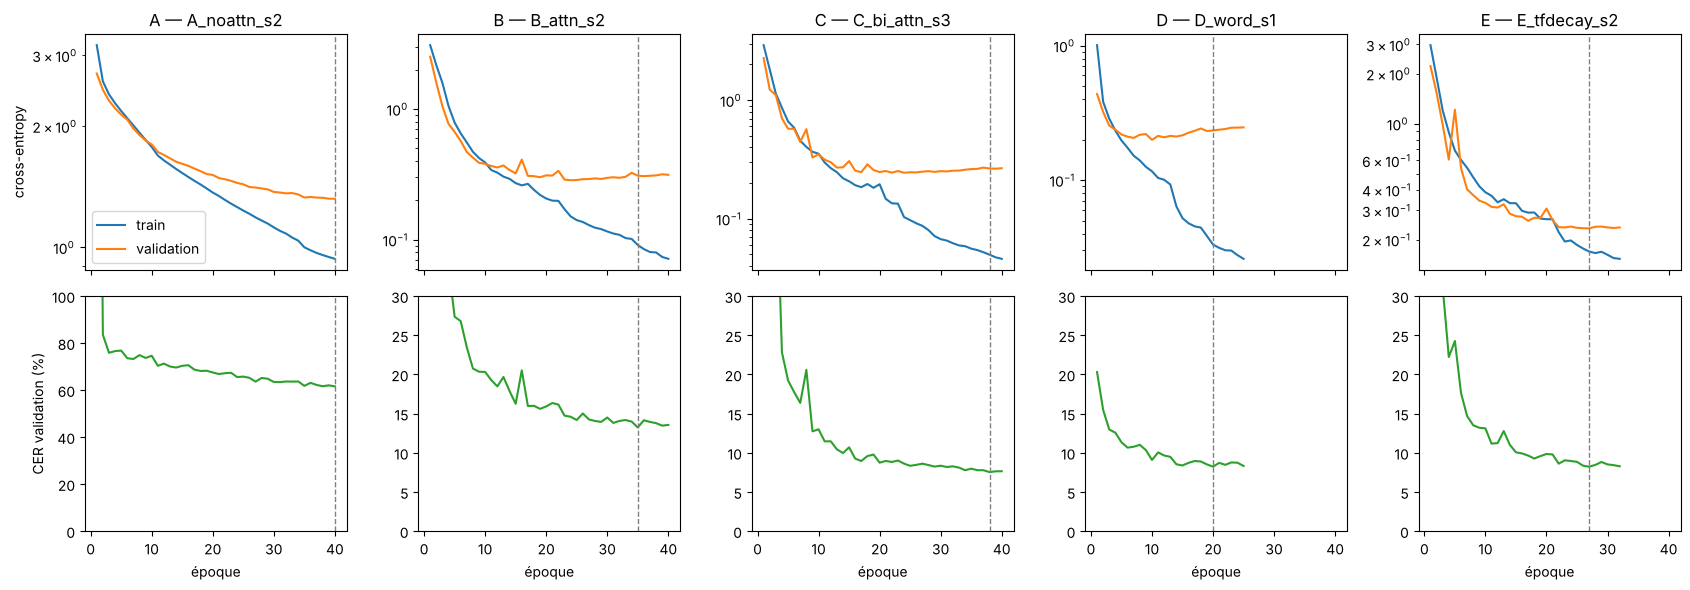

In [ ]:
MEILLEUR_VAL = {}
for e in EXPERIMENTS:
    runs = [f"{CONFIGS[e]['name']}_s{s}" for s in SEEDS[e]]
    MEILLEUR_VAL[e] = min(runs, key=lambda r: json.load(open(MODELS_DIR / r / "train_summary.json"))["best_val_cer"])

fig, axes = plt.subplots(2, 5, figsize=(17, 6), sharex=True)
for k, (e, run) in enumerate(MEILLEUR_VAL.items()):
    h = pd.DataFrame(json.load(open(MODELS_DIR / run / "train_summary.json"))["history"])
    best = h.loc[h.val_cer.idxmin(), "epoch"]
    ax = axes[0, k]
    ax.plot(h.epoch, h.train_loss, label="train"); ax.plot(h.epoch, h.val_loss, label="validation")
    ax.set_yscale("log"); ax.set_title(f"{e} — {run}"); ax.axvline(best, color="grey", ls="--", lw=1)
    ax = axes[1, k]
    ax.plot(h.epoch, 100 * h.val_cer, color="C2"); ax.axvline(best, color="grey", ls="--", lw=1)
    ax.set_ylim(0, 100 if e == "A" else 30); ax.set_xlabel("époque")
axes[0, 0].set_ylabel("cross-entropy"); axes[1, 0].set_ylabel("CER validation (%)"); axes[0, 0].legend()
plt.tight_layout(); plt.show()

**Lecture des courbes**

* **A sous-apprend** : sa perte reste élevée et baisse encore à la limite de 40 époques. Le vecteur unique limite le modèle.
* **B, C et D surapprennent légèrement** : la perte de validation remonte après l'époque 24 environ, mais le CER de validation continue de baisser. Comme on garde le meilleur CER et qu'on arrête à temps, l'effet reste contrôlé.
* **E** a une perte d'entraînement plus haute, car elle est calculée en partie sur ses propres prédictions.

### 7.2 Évaluation sur le test
On évalue le **test une seule fois**, avec quatre métriques :

* **CER** ↓ : erreurs caractère par caractère (métrique principale) ;
* **exact match** ↑ : exemples entièrement corrects ;
* **BLEU** ↑ : mots en commun avec la référence ;
* **perplexité** ↓ : à quel point le modèle hésite.

In [ ]:
def exact_match(preds, refs):
    return float(np.mean([p == r for p, r in zip(preds, refs)]))

def bleu(preds, refs):
    return sacrebleu.corpus_bleu(preds, [refs]).score

def perplexity(model, loader):
    crit_sum = nn.CrossEntropyLoss(ignore_index=PAD_ID, reduction="sum")     # somme (et non moyenne) pour pondérer par caractère
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for _, src, src_len, tgt in loader:
            src, src_len, tgt = src.to(DEVICE), src_len.to(DEVICE), tgt.to(DEVICE)
            logits = model(src, src_len, tgt, 1.0)
            total += crit_sum(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1)).item()
            n += (tgt[:, 1:] != PAD_ID).sum().item()
    return math.exp(total / n)

def load_best(run):
    # recharge le meilleur modèle d'un run avec ses vocabulaires
    ck = torch.load(MODELS_DIR / run / "best.pt", map_location=DEVICE, weights_only=False)
    model = Seq2Seq(**ck["config"]).to(DEVICE)
    model.load_state_dict(ck["state_dict"])
    model.eval()
    sv = CharVocab.load(MODELS_DIR / run / "src_vocab.json")
    tv = CharVocab.load(MODELS_DIR / run / "tgt_vocab.json")
    return model, sv, tv, ck

def evaluate_test(run, level):
    model, sv, tv, ck = load_best(run)
    ex = EX[level]["test"][:HP["max_eval"] or None]
    loader = DataLoader(TranslitDataset(ex, sv, tv), batch_size=128, collate_fn=collate)
    refs = [e["tgt"] for e in ex]
    preds = predict(model, loader, tv)
    metrics = {"run": run, "CER": cer(preds, refs), "EM": exact_match(preds, refs),
               "BLEU": bleu(preds, refs), "PPL": perplexity(model, loader), "epoch": ck["epoch"]}
    return metrics, preds

# quels runs ont un modèle sauvegardé ?
available = [(e, s) for e in EXPERIMENTS for s in SEEDS[e] if (MODELS_DIR / f"{CONFIGS[e]['name']}_s{s}" / "best.pt").exists()]
print(len(available), "runs disponibles :", [f"{e}{s}" for e, s in available])

13 runs disponibles : ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3', 'D1', 'E1', 'E2', 'E3']


In [ ]:
rows, PREDS = [], {}
for exp, seed in available:
    run = f"{CONFIGS[exp]['name']}_s{seed}"
    metrics, PREDS[run] = evaluate_test(run, CONFIGS[exp]["level"])
    val_cer = json.load(open(MODELS_DIR / run / "train_summary.json"))["best_val_cer"]
    rows.append({"exp": exp, "seed": seed, **metrics, "CER val": val_cer})
RES = pd.DataFrame(rows)
RES.to_csv(RESULTS_DIR / "test_metrics_per_run.csv", index=False)
RES[["run", "CER val", "CER", "EM", "BLEU", "PPL", "epoch"]].round(4)

,run,CER val,CER,EM,BLEU,PPL,epoch
0,A_noattn_s1,0.6233,0.6051,0.1694,8.6186,3.6198,39
1,A_noattn_s2,0.6159,0.6040,0.1891,8.6026,3.5336,40
2,A_noattn_s3,0.7495,0.7478,0.1114,1.9594,9.9640,3
3,B_attn_s1,0.1380,0.1318,0.4200,55.5967,1.3017,31
4,B_attn_s2,0.1323,0.1292,0.4246,56.0447,1.2930,35
5,B_attn_s3,0.1350,0.1338,0.4362,55.8594,1.3234,37
6,C_bi_attn_s1,0.0805,0.0698,0.5452,68.0774,1.2458,39
7,C_bi_attn_s2,0.0802,0.0779,0.5499,66.8985,1.2395,31
8,C_bi_attn_s3,0.0753,0.0744,0.5383,67.3134,1.2537,38
9,D_word_s1,0.0823,0.0787,0.8692,62.6495,1.2297,20


In [ ]:
# tableau final : moyenne ± écart-type sur les seeds (D n'a qu'une seed, donc pas d'écart-type)
def mean_std(x, scale=1):
    s = f"{scale * x.mean():.2f}"
    return s + (f" ± {scale * x.std(ddof=1):.2f}" if len(x) > 1 else "")

TABLE = pd.DataFrame([{"Exp": e, "Modèle": CONFIGS[e]["name"] + (" (mots isolés)" if e == "D" else ""), "seeds": len(g),
                       "CER % ↓": mean_std(g.CER, 100), "Exact match %": mean_std(g.EM, 100),
                       "BLEU": mean_std(g.BLEU), "Perplexité": mean_std(g.PPL)}
                      for e, g in RES.groupby("exp")])
TABLE.to_csv(RESULTS_DIR / "comparison_A_to_E.csv", index=False)
print("⚠ D est évalué sur des mots isolés (autre granularité, 1 seed) : ses métriques ne sont pas comparables aux autres.")
TABLE

⚠ D est évalué sur des mots isolés (autre granularité, 1 seed) : ses métriques ne sont pas comparables aux autres.


,Exp,Modèle,seeds,CER % ↓,Exact match %,BLEU,Perplexité
0,A,A_noattn,3,65.23 ± 8.27,15.66 ± 4.04,6.39 ± 3.84,5.71 ± 3.69
1,B,B_attn,3,13.16 ± 0.23,42.69 ± 0.84,55.83 ± 0.23,1.31 ± 0.02
2,C,C_bi_attn,3,7.40 ± 0.41,54.45 ± 0.58,67.43 ± 0.60,1.25 ± 0.01
3,D,D_word (mots isolés),1,7.87,86.92,62.65,1.23
4,E,E_tfdecay,3,8.02 ± 0.35,51.24 ± 0.41,65.92 ± 0.53,1.24 ± 0.01


### 7.3 Comparaison avec la baseline
Le meilleur run de chaque modèle est choisi sur la **validation**, jamais sur le test.

{'A': 'A_noattn_s2', 'B': 'B_attn_s2', 'C': 'C_bi_attn_s3', 'D': 'D_word_s1', 'E': 'E_tfdecay_s2'}


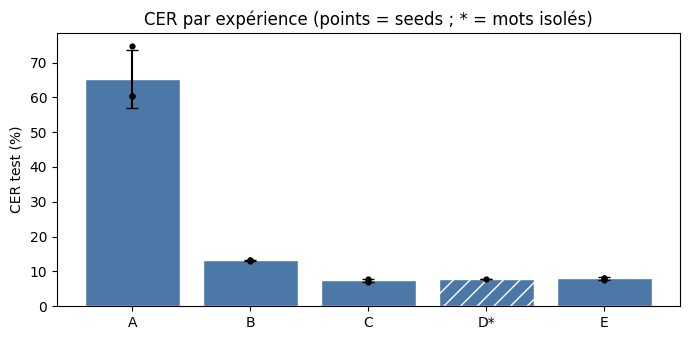

In [ ]:
BEST = {e: g.loc[g["CER val"].idxmin(), "run"] for e, g in RES.groupby("exp")}
print(BEST)

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, (e, g) in enumerate(RES.groupby("exp")):
    err = 100 * g.CER.std(ddof=1) if len(g) > 1 else 0
    ax.bar(i, 100 * g.CER.mean(), yerr=err, capsize=4, color="#4C78A8", edgecolor="white", hatch="//" if e == "D" else None)
    ax.scatter([i] * len(g), 100 * g.CER, color="k", s=12, zorder=3)      # un point par seed
ax.set_xticks(range(RES.exp.nunique()))
ax.set_xticklabels([e + ("*" if e == "D" else "") for e in sorted(RES.exp.unique())])
ax.set_ylabel("CER test (%)")
ax.set_title("CER par expérience (points = seeds ; * = mots isolés)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "cer_comparison.png", dpi=150); plt.show()

In [ ]:
# Résumé chiffré : ce que chaque idée apporte (CER moyen, sans D car non comparable)
mean_cer = RES[RES.exp != "D"].groupby("exp").CER.mean() * 100
for a, b, idea in [("A", "B", "attention"), ("B", "C", "BiLSTM"), ("C", "E", "teacher forcing décroissant")]:
    if a in mean_cer and b in mean_cer:
        print(f"{idea:30s} ({a} → {b}) : CER {mean_cer[a]:.2f} % → {mean_cer[b]:.2f} %  ({mean_cer[b]-mean_cer[a]:+.2f} points)")

attention                      (A → B) : CER 65.23 % → 13.16 %  (-52.07 points)
BiLSTM                         (B → C) : CER 13.16 % → 7.40 %  (-5.76 points)
teacher forcing décroissant    (C → E) : CER 7.40 % → 8.02 %  (+0.61 points)



> * **Attention** (A → B) : le CER passe de 65 % à 13 %. C'est le gain décisif.
> * **BiLSTM** (B → C) : il descend encore à 7,4 %, avec toutefois plus de paramètres.
> * **Teacher forcing décroissant** (C → E) : aucun gain.
> * **Meilleur modèle : C**, avec un CER de test de 7,40 ± 0,41 %.

## 8. Exemples générés

### 8.1 La génération pas à pas
On suit le modèle C sur un message court. À chaque pas : le caractère Arabizi que regarde l'attention, les 3 lettres arabes les plus probables, et celle qui est choisie.

In [ ]:
# génération greedy détaillée, pas à pas
model, sv, tv, _ = load_best(BEST["C"])
texte = "3andi 5ouya"
ids = sv.encode(texte)
src, src_len = torch.tensor([ids], device=DEVICE), torch.tensor([len(ids)])
show = lambda c: "␣" if c == " " else c
lignes, sortie = [], []
with torch.no_grad():
    enc_out, keys, mask, state = model.encode(src, src_len)
    y = torch.tensor([SOS_ID], device=DEVICE) # le décodeur commence par <SOS>
    for t in range(1, 3 * len(ids)):
        logits, state, alpha = model.decoder.step(y, state, enc_out, keys, mask)
        proba = F.softmax(logits, dim=-1)[0]   # probabilités des 122 caractères arabes
        top_p, top_i = proba.topk(3)
        choix = int(top_i[0]) # greedy : le plus probable
        lignes.append({"pas": t,
                       "regarde": show(texte[int(alpha[0].argmax())]),
                       "top-3 (probabilité)": "  |  ".join(f"{show(tv.itos[i])} {p:.2f}" for p, i in zip(top_p.tolist(), top_i.tolist())),
                       "choisi": show(tv.itos[choix])})
        if choix == EOS_ID:  # critère d'arrêt
            break
        sortie.append(choix)
        y = torch.tensor([choix], device=DEVICE) # la prédiction devient l'entrée suivante
print(texte, "→", tv.decode(sortie))
pd.DataFrame(lignes)

### 8.2 Réussites et échecs
Le modèle C fait au moins une erreur sur 398 fenêtres de test sur 862. On regarde d'abord des réussites, puis les erreurs.

In [ ]:
# exemples parfaitement translittérés qui contiennent un chiffre (3, 5, 7, 9)
run = BEST["C"]
ex = EX["chunk"]["test"][:len(PREDS[run])]
reussites = [(e["src"], e["tgt"]) for e, p in zip(ex, PREDS[run]) if p == e["tgt"] and re.search("[3579]", e["src"])]
print(f"{sum(p == e['tgt'] for e, p in zip(ex, PREDS[run]))} fenêtres parfaites sur {len(ex)}, dont {len(reussites)} avec un chiffre arabizi")
pd.DataFrame(reussites[:8], columns=["Arabizi", "référence = prédiction"])

In [ ]:
run = BEST["C"]
ex = EX["chunk"]["test"][:len(PREDS[run])]
errors = [(e["src"], e["tgt"], p) for e, p in zip(ex, PREDS[run]) if e["tgt"] != p]
print(f"{run} : {len(errors)} exemples faux sur {len(ex)}")
pd.DataFrame(errors[:10], columns=["Arabizi", "référence", "prédiction"])

C_bi_attn_s3 : 398 exemples faux sur 862


,Arabizi,référence,prédiction
0,βēšŧ jàâàŵ šŭr ƒãčëβǿøk,βēšŧ جوّ šŭr فايسبوك,<UNK><UNK>š<UNK> جوّة <UNK><UNK>ر يسيّوك ك
1,βēšŧ jàâàŵ šŭr ƒãčëβǿøk,βēšŧ جوّ šŭr فايسبوك,<UNK><UNK>š<UNK> جوّة <UNK><UNK>ر يسيّوك ك
2,mou3ayna naghsslou beha dbach wala kifech,معينة نغسلوا بها دبش ولا كيفاش,مععينا نغسّلوا بها دبش ولا كيفاش
3,# we_dream .,# we_dream .,# والدرام .
4,ha enta wela amie mchi wela,ها انتا ولا amie ماشي ولا,ها انتا ولا amie مشي ولا
5,§ § mat . thay3ouhech,§ § مات . ضيعوهاش,§ § مات . ثيعوهش
6,man7eb n3ich el 7ya bel mout,ما نحبّ نعيش ال حياة بال موت,ما نحبّ نعيش ال حية بال موت
7,noufa kima weld el jara b,نوفى كيما ولد ال جارة ب,نوفة كيما ولد ال جرّة ب
8,chi5a teblè,شيخة تبلى,شيخة تبلا
9,asma3 rap klab a7na rapna 39od,اسمع rap كلاب احنا رابنا عقد,اسمع rap كلاب احنا ربنا عقد


In [ ]:
# Cause principale de chaque erreur (classement automatique simple)
def cause(src, ref, pred):
    if "<UNK>" in pred:
        return "caractère inconnu (lettres stylisées → <UNK>)"
    s, r, p = src.split(), ref.split(), pred.split()
    if len(p) != len(r):
        return "mots fusionnés ou coupés"
    if len(s) == len(r) and any(rw != pw and sw == rw for sw, rw, pw in zip(s, r, p)):
        return "mot étranger mal recopié"
    return "orthographe d'un mot arabizi"

causes = Counter(cause(*err) for err in errors)
pd.DataFrame([{"cause": c, "fenêtres": n, "%": round(100 * n / len(errors), 1)} for c, n in causes.most_common()])

**Pourquoi le modèle se trompe-t-il ?**

* **Lettres stylisées** (`βēšŧ`) : absentes du train, elles deviennent `<UNK>`.
* **Voyelles longues** : pour `7ya`, le modèle écrit حية au lieu de حياة.
* **Lettres ambiguës** : `th` peut donner ث ou ض.
* **Mots étrangers translittérés à tort** : `we_dream` n'est pas recopié.

Il n'y a qu'**une seule référence** : beaucoup de ces erreurs sont des variantes d'orthographe qu'un lecteur arabophone comprend souvent quand même.

### 8.3 Greedy ou beam search : la comparaison
On compare les deux méthodes sur les 100 premières fenêtres du test, avec le même modèle C.

In [ ]:
N_BEAM = 100
model, sv, tv, _ = load_best(BEST["C"])
ex = EX["chunk"]["test"][:N_BEAM]
refs = [e["tgt"] for e in ex]
greedy = [transliterate(model, sv, tv, e["src"], beam=0)[0] for e in ex]
t0 = time.time()
beam = [transliterate(model, sv, tv, e["src"], beam=5)[0] for e in ex]
print(f"{len(ex)} exemples | CER greedy {100*cer(greedy, refs):.2f} % | CER beam(5) {100*cer(beam, refs):.2f} % | beam : {time.time()-t0:.0f} s")
print("exemples où les deux sorties diffèrent :", sum(g != b for g, b in zip(greedy, beam)))

100 exemples | CER greedy 11.52 % | CER beam(5) 10.28 % | beam : 12 s
exemples où les deux sorties diffèrent : 9


→ **Résultat** : le beam search abaisse le CER de 11,52 % à 10,28 %, mais il ne change la sortie que pour 9 exemples sur 100. Le modèle C est déjà sûr de lui, donc le greedy se trompe rarement de chemin. Le beam search est aussi plus lent (5 hypothèses au lieu d'une). Le **greedy reste donc le mode par défaut**, et le beam search une option.



### 8.6 Essai sur de nouveaux messages

In [ ]:
def translit_line(text, run):
    model, sv, tv, _ = load_best(run)
    words = normalize(text).split()
    chunks = [" ".join(words[i:i + HP["chunk"]]) for i in range(0, len(words), HP["chunk"])]
    return " ".join(transliterate(model, sv, tv, c)[0] for c in chunks)

NEW_SENTENCES = ["3aslema", "ena n7eb tounes", "chnowa a7welek", "3andi 5ouya w o5ti", "9adech soum hedha"]
pd.DataFrame({"Arabizi": NEW_SENTENCES,
              **{f"{e} ({BEST[e]})": [translit_line(s, BEST[e]) for s in NEW_SENTENCES] for e in ["A", "B", "C", "E"] if e in BEST}})

,Arabizi,A (A_noattn_s2),B (B_attn_s2),C (C_bi_attn_s3),E (E_tfdecay_s2)
0,3aslema,علاصمة,عالسلامة,عالسلامة,عالسلامة
1,ena n7eb tounes,انا نحبّوا تونس,انا نحبّ تونس,انا نحبّ تونس,انا نحبّ تونس
2,chnowa a7welek,شنوة وحدة,شنوة احوالك,شنوة احولك,شنوة احوالك
3,3andi 5ouya w o5ti,عندي و قويّة ؟؟ و,عندي خويا و اختي,عندي خويا و اختي,عندي خويا و اختي
4,9adech soum hedha,قدّاش سوم هاذا,قدّاش سوم هاذا,قدّاش سوم هاذا,قدّاش سوم هاذا


→ A, sans attention, invente des mots. Les modèles avec attention écrivent tous un arabe correct ou très proche.

## 9. Discussion

| Question | Réponse |
|---|---|
| Le modèle apprend-il la tâche ? | Oui à partir de B. C écrit sans faute 54 % des fenêtres de 6 mots. A n'y arrive pas (CER > 60 %). |
| Y a-t-il surapprentissage ? | Léger pour B, C et D, contrôlé par l'early stopping. A sous-apprend. |
| L'attention aide-t-elle ? | Oui, nettement : 52 points de CER en moins, et des résultats stables entre seeds. |
| Plus de paramètres = mieux ? | Pas forcément : C (+46 % de paramètres) gagne, mais E, de même taille que C, ne gagne rien. |
| Quelles entrées sont difficiles ? | Les caractères jamais vus, les mots mêlant arabe et français, les orthographes rares. |
| Limites | Petit corpus, une seule référence, contexte de 6 mots, aucune copie des mots étrangers. |

## 10. Conclusion
Ce projet est parti d'un problème simple : ma mère lit le français et l'arabe, mais les chiffres de l'Arabizi lui rendent mes messages illisibles. Un Encodeur–Décodeur sans attention n'y suffit pas (CER 65 %). L'**attention de Bahdanau** change tout, et le **BiLSTM** donne le meilleur modèle, C, avec **7,40 ± 0,41 %** de CER sur le test : plus de 92 % des caractères générés sont corrects.


---
### Bonus 
| Bonus | Ce qu'il fait | Où |
|---|---|---|
| **Application web** | on écrit en Arabizi sur un iPhone, le texte arabe s'affiche sur un Nokia 3310 | `app/` (HTML, CSS, JavaScript) |
| **Serveur Python** | charge le meilleur modèle (C) et expose l'API `/api/transliterate` | `backend/server.py` |
| **Options de l'interface** | beam search, comparaison avec le modèle A, carte d'attention interactive | `app/app.js` |
| **OCR** | lit le texte d'une capture d'écran (Tesseract) avant de le translittérer | `backend/ocr.py` |
